<div class="alert alert-info">
    <h1 style="margin-top: 0;">Junior Data Analyst — Starter Notebook - Tavor Levine</h1>
  <b></b> 
</div>


<div class="alert alert-info">
    <h2 style="margin-top: 0;">Part A</h2>
  <b></b> 
</div>

In [35]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from PIL import Image

In [2]:
DATA_DIR = Path(".")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, "test:", test.shape)
display(train.head())


train: (168, 10) test: (72, 8)


,image_id,file,batch,line,camera,shift,timestamp_utc,exposure_setting,inspector_label,inspector_type
0,IMG_0004,images/IMG_0004.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T07:45:00Z,NORMAL,1,stain
1,IMG_0005,images/IMG_0005.jpg,BATCH-A,LINE-1,CAM-B,DAY,2026-11-02T08:00:00Z,LOW,0,none
2,IMG_0006,images/IMG_0006.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T08:15:00Z,NORMAL,1,stain
3,IMG_0007,images/IMG_0007.jpg,BATCH-A,LINE-1,CAM-B,NIGHT,2026-11-02T08:30:00Z,LOW,1,stain
4,IMG_0008,images/IMG_0008.jpg,BATCH-A,LINE-2,CAM-B,DAY,2026-11-02T08:45:00Z,NORMAL,0,none


In [3]:
print("Train columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())

print("\nMissing values:")
print(train.isnull().sum())

print("\nLabel distribution:")
print(train["inspector_label"].value_counts())

Train columns:
['image_id', 'file', 'batch', 'line', 'camera', 'shift', 'timestamp_utc', 'exposure_setting', 'inspector_label', 'inspector_type']

Test columns:
['image_id', 'file', 'batch', 'line', 'camera', 'shift', 'timestamp_utc', 'exposure_setting']

Missing values:
image_id            0
file                0
batch               0
line                0
camera              0
shift               0
timestamp_utc       0
exposure_setting    0
inspector_label     0
inspector_type      0
dtype: int64

Label distribution:
inspector_label
0    112
1     56
Name: count, dtype: int64


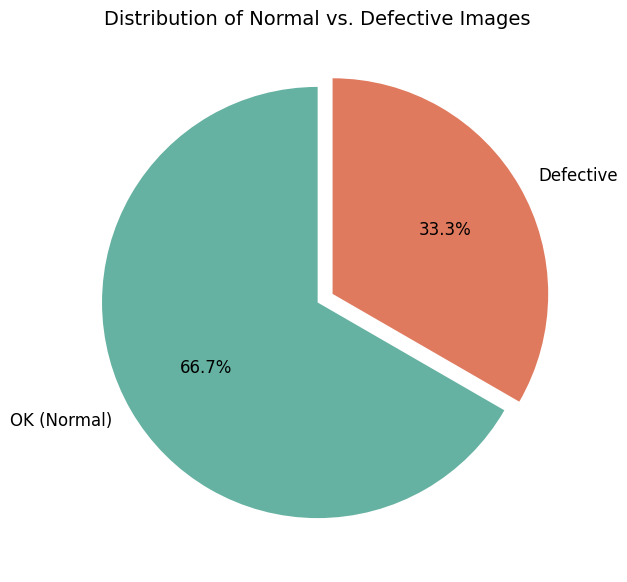

In [4]:
label_counts = train["inspector_label"].value_counts().sort_index()

labels = ["OK (Normal)", "Defective"]
colors = ["#66B2A2", "#E07A5F"]

plt.figure(figsize=(7, 7))

plt.pie(
    label_counts,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    explode=(0, 0.08),
    textprops={"fontsize": 12}
)

plt.title("Distribution of Normal vs. Defective Images", fontsize=14)
plt.show()

The training dataset contains 168 images, with 112 normal images (66.7%) and 56 defective images (33.3%). This indicates a moderate class imbalance, with twice as many normal images as defective images.

### Data Quality Check

In [5]:
print("Duplicate image_id:")
print(train["image_id"].duplicated().sum())

print("\nDuplicate file:")
print(train["file"].duplicated().sum())

print("\nDuplicate rows:")
print(train.duplicated().sum())

Duplicate image_id:
0

Duplicate file:
0

Duplicate rows:
0


In [6]:
print("Missing values in test:")
display(test.isnull().sum())

print("\nDuplicate image_id in test:")
print(test["image_id"].duplicated().sum())

Missing values in test:


image_id            0
file                0
batch               0
line                0
camera              0
shift               0
timestamp_utc       0
exposure_setting    0
dtype: int64


Duplicate image_id in test:
0


The initial data quality analysis found no missing values or duplicate records in the training and test datasets. All required metadata fields are populated, and no duplicate image IDs or file names were identified. Therefore, no immediate data cleaning is required at this stage.

### Comparison Between the Cameras

In [8]:
camera_stats = train.groupby("camera")["inspector_label"].agg(
    total="count",
    defective="sum",
    defect_rate="mean"
)

camera_stats["defect_rate"] *= 100

display(camera_stats)

,total,defective,defect_rate
camera,,,
CAM-A,95,30,31.578947
CAM-B,73,26,35.616438


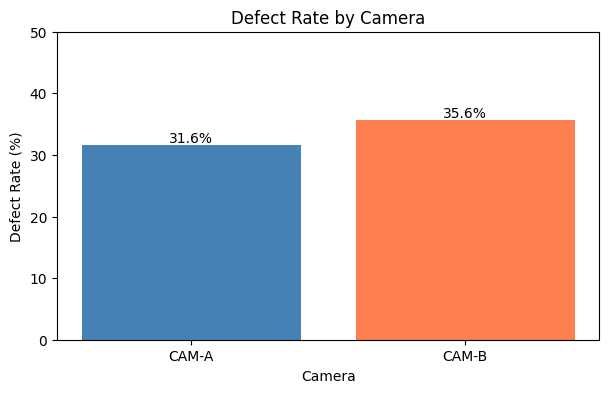

In [9]:
plt.figure(figsize=(7, 4))

bars = plt.bar(
    camera_stats.index,
    camera_stats["defect_rate"],
    color=["steelblue", "coral"]
)

plt.title("Defect Rate by Camera")
plt.xlabel("Camera")
plt.ylabel("Defect Rate (%)")
plt.ylim(0, 50)

# Display percentage values above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{bar.get_height():.1f}%',
        ha="center"
    )

plt.show()

**Insight**

CAM-B shows a slightly higher defect rate (35.62%) compared to CAM-A (31.58%).

However, the difference is relatively small and does not necessarily indicate a camera-related issue. Further analysis is needed to determine whether this difference is associated with production batches, production lines, or imaging conditions.

<div class="alert alert-info">
    <h2 style="margin-top: 0;">Part B</h2>
  <b></b> 
</div>

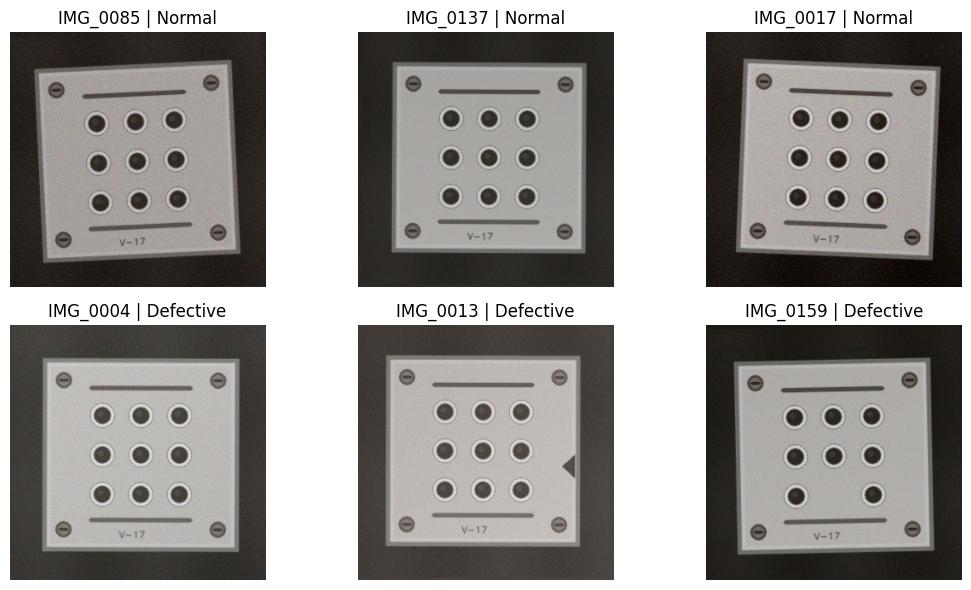

In [16]:
from PIL import Image

# Select 3 normal and 3 defective images
normal_samples = train[train["inspector_label"] == 0].sample(
    n=3, random_state=42
)

defective_samples = train[train["inspector_label"] == 1].sample(
    n=3, random_state=42
)

samples = pd.concat([normal_samples, defective_samples])

fig, axes = plt.subplots(2, 3, figsize=(11, 6))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    img = Image.open(DATA_DIR / row["file"])
    ax.imshow(img)
    label = "Normal" if row["inspector_label"] == 0 else "Defective"
    ax.set_title(f"{row['image_id']} | {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Visual inspection revealed two differences in the defective images: some images show a uniform transparent layer across the surface, while another image contains only 8 dots instead of the expected 9. These observations suggest that defects may appear in different forms, affecting both the overall visual appearance and the product structure.

In [17]:
#Function 
def extract_features(image_path):
    # Open image and convert to grayscale
    img = Image.open(image_path).convert("L")

    # Convert image to NumPy array
    img_array = np.array(img, dtype=np.float32)

    # Calculate features
    brightness = img_array.mean()
    contrast = img_array.std()

    return brightness, contrast

In [18]:
features = []

for _, row in train.iterrows():
    image_path = DATA_DIR / row["file"]

    brightness, contrast = extract_features(image_path)

    features.append({
        "image_id": row["image_id"],
        "brightness": brightness,
        "contrast": contrast,
        "label": row["inspector_label"]
    })

features_df = pd.DataFrame(features)

display(features_df.head())

,image_id,brightness,contrast,label
0,IMG_0004,124.239655,62.632252,1
1,IMG_0005,107.832619,69.675613,0
2,IMG_0006,107.967964,75.878967,1
3,IMG_0007,103.206558,69.724205,1
4,IMG_0008,102.009293,66.322678,0


In [19]:
feature_summary = features_df.groupby("label").agg({
    "brightness": ["mean", "median"],
    "contrast": ["mean", "median"]
})

display(feature_summary)

brightness               contrast           
             mean      median       mean     median
label                                              
0      114.165833  114.325165  66.826324  66.599121
1      112.312546  111.129784  65.064819  65.077209

Both mean and median brightness and contrast values are slightly higher in normal images compared to defective images. The relatively small differences suggest that these features alone may not be sufficient to reliably distinguish between the two classes.

Text(0, 0.5, 'Average Brightness')

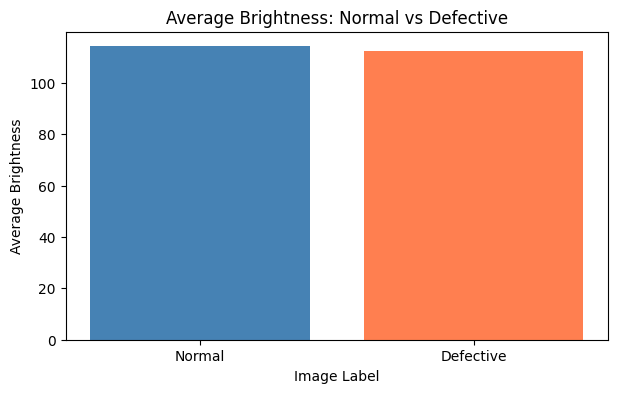

In [20]:
plt.figure(figsize=(7, 4))

plt.bar(
    ["Normal", "Defective"],
    [
        feature_summary.loc[0, ("brightness", "mean")],
        feature_summary.loc[1, ("brightness", "mean")]
    ],
    color=["steelblue", "coral"]
)

plt.title("Average Brightness: Normal vs Defective")
plt.xlabel("Image Label")
plt.ylabel("Average Brightness")


Both mean and median values were calculated for brightness and contrast. Since the results were relatively close, only the mean brightness values are presented in the graph for simplicity. Normal images have a slightly higher average brightness (114.17) compared to defective images (112.31). However, the difference is small, suggesting that brightness alone may not be sufficient to reliably distinguish between the two classes.

<div class="alert alert-info">
    <h2 style="margin-top: 0;">Part C</h2>
  <b></b> 
</div>

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score

In [22]:
# Select features and labels
X = features_df[["brightness", "contrast"]]
y = features_df["label"]

# Split data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

Training set: (126, 2)
Validation set: (42, 2)

Training labels:
label
0    84
1    42
Name: count, dtype: int64

Validation labels:
label
0    28
1    14
Name: count, dtype: int64


In [23]:
# Create the model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


**Model Selection – Logistic Regression**

I chose Logistic Regression as baseline classification model because it is simple, interpretable, and suitable for a binary classification task (normal vs. defective). Since my dataset is relatively small and I use only two basic image features (brightness and contrast), Logistic Regression provides a good starting point without introducing unnecessary model complexity.

I also applied StandardScaler to standardize the features so that brightness and contrast have a similar scale. This is important because Logistic Regression can be sensitive to differences in feature scales. Scaling helps the model learn more effectively and prevents features with larger numerical values from having an unintended influence on the model.

In [24]:
# Predict labels
val_predictions = model.predict(X_val)

# Predict probability of defect (class 1)
val_scores = model.predict_proba(X_val)[:, 1]

print("Predictions:", val_predictions)
print("Scores:", val_scores)

Predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0]
Scores: [0.3006114  0.35625565 0.33013354 0.32546209 0.32295637 0.44352553
 0.23520667 0.30721658 0.27592687 0.33749391 0.41943444 0.33372403
 0.3692475  0.28503599 0.38653525 0.28308536 0.47395948 0.22808581
 0.2831576  0.33038097 0.27637686 0.32524836 0.2899935  0.32872791
 0.31789074 0.37473334 0.31016558 0.24909893 0.34430811 0.37134858
 0.33070899 0.29298623 0.40368609 0.30905668 0.44203768 0.30645368
 0.35773175 0.27211302 0.25460891 0.2910328  0.40419393 0.27567841]


<div class="alert alert-info">
    <h2 style="margin-top: 0;">Part D</h2>
  <b></b> 
</div>

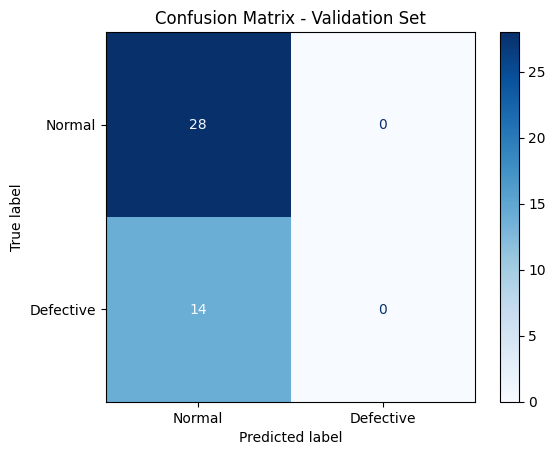

Precision: 0.0
Recall: 0.0


In [25]:
# Calculate confusion matrix
cm = confusion_matrix(y_val, val_predictions, labels=[0, 1])

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Defective"]
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Validation Set")
plt.show()

# Calculate metrics
precision = precision_score(y_val, val_predictions, zero_division=0)
recall = recall_score(y_val, val_predictions, zero_division=0)

print("Precision:", precision)
print("Recall:", recall)

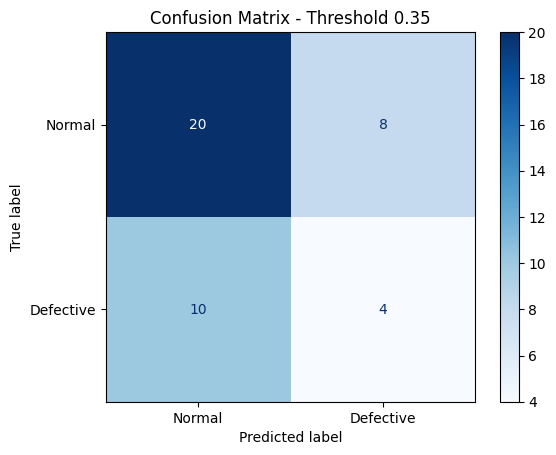

Precision: 0.3333333333333333
Recall: 0.2857142857142857


In [26]:
# Use a lower decision threshold
threshold = 0.35

val_predictions_new = (val_scores >= threshold).astype(int)

# Calculate new metrics
cm_new = confusion_matrix(y_val, val_predictions_new, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_new,
    display_labels=["Normal", "Defective"]
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Threshold 0.35")
plt.show()

precision_new = precision_score(
    y_val, val_predictions_new, zero_division=0
)
recall_new = recall_score(
    y_val, val_predictions_new, zero_division=0
)

print("Precision:", precision_new)
print("Recall:", recall_new)

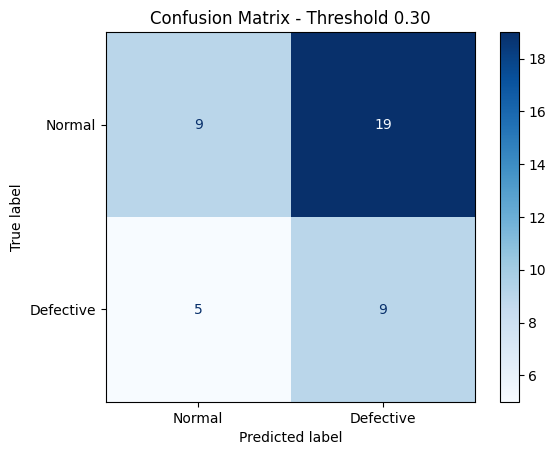

Precision: 0.32142857142857145
Recall: 0.6428571428571429


In [27]:
threshold = 0.30

val_predictions_030 = (val_scores >= threshold).astype(int)

cm_030 = confusion_matrix(
    y_val, val_predictions_030, labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_030,
    display_labels=["Normal", "Defective"]
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Threshold 0.30")
plt.show()

print("Precision:", precision_score(
    y_val, val_predictions_030, zero_division=0
))
print("Recall:", recall_score(
    y_val, val_predictions_030, zero_division=0
))

**Threshold Selection**

I decided to lower the classification threshold from the default value of 0.5 to 0.30 in order to improve Recall. Since the main goal of this task is to identify defective images, I considered it more important to detect as many defective images as possible, even if this resulted in more false positives. Lowering the threshold allowed the model to classify more images as potentially defective, increasing its ability to detect actual defects. Although Precision decreased slightly, Recall improved significantly, making 0.30 a more suitable threshold for this task.

In [28]:
threshold = 0.30
val_predictions = (val_scores >= threshold).astype(int)

val_results = pd.DataFrame({
    "index": X_val.index,
    "actual": y_val,
    "predicted": val_predictions,
    "score": val_scores
})

# Find misclassified images
errors = val_results[
    val_results["actual"] != val_results["predicted"]
]

display(errors.sort_values("score").head())

,index,actual,predicted,score
77,77,1,0,0.235207
19,19,1,0,0.272113
13,13,1,0,0.275678
122,122,1,0,0.291033
109,109,1,0,0.292986


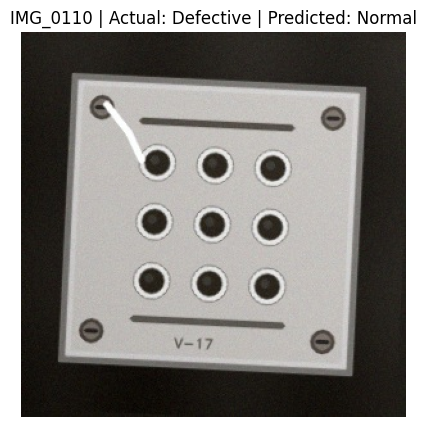

In [29]:
idx = 77

row = train.loc[idx]
img = Image.open(DATA_DIR / row["file"])

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(
    f"{row['image_id']} | Actual: Defective | Predicted: Normal"
)
plt.axis("off")
plt.show()

The selected image was labeled as defective, but the model classified it as normal. Visual inspection revealed a scribbled line in the upper-left area of the image, while the rest of the image appeared normal. Since the model relies only on global brightness and contrast features, it may fail to detect small, localized defects that do not significantly affect the overall image statistics.

### Conclusions

The dataset contains 168 labeled images, with approximately two-thirds classified as normal and one-third as defective.

The defect rates across the two cameras were relatively similar, with no substantial difference observed.

Basic image features, brightness and contrast, showed only small differences between normal and defective images.

A Logistic Regression model was trained using these two features. Lowering the decision threshold to 0.30 improved recall to 64.29%, while precision remained relatively low at 32.14%.

The results indicate that brightness and contrast alone are not sufficient to reliably identify defects, particularly localized defects that do not significantly affect the overall image statistics.

If more time had been available, I would have liked to explore a more advanced classification model using a wider range of image features, such as sharpness, edge detection, and texture. This could provide a more comprehensive analysis of the images and potentially improve the model's ability to identify different types of defects.

### AI Usage

AI tools were used to assist with code development, debugging, understanding image-processing techniques, selecting a baseline classification model, and interpreting evaluation metrics. The analysis, visual inspection, and interpretation of results were reviewed throughout the process.

<div class="alert alert-info">
    <h2 style="margin-top: 0;">End Part C</h2>
  <b></b> 
</div>

In [30]:
test_features = []

for _, row in test.iterrows():
    image_path = DATA_DIR / row["file"]

    brightness, contrast = extract_features(image_path)

    test_features.append({
        "brightness": brightness,
        "contrast": contrast
    })

X_test = pd.DataFrame(test_features)

print(X_test.shape)
display(X_test.head())

(72, 2)


,brightness,contrast
0,101.023125,59.232414
1,100.707321,64.170967
2,107.397400,68.550079
3,119.204926,63.941662
4,118.581619,72.363617


In [31]:
# Predict defect probabilities
test_scores = model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
threshold = 0.30
test_predictions = (test_scores >= threshold).astype(int)

print("Number of predictions:", len(test_predictions))
print("Predicted labels:")
print(pd.Series(test_predictions).value_counts().sort_index())

Number of predictions: 72
Predicted labels:
0    23
1    49
Name: count, dtype: int64


In [33]:
predictions = pd.DataFrame({
    "image_id": test["image_id"],
    "predicted_defect": test_predictions,
    "score": test_scores
})

predictions.to_csv("predictions.csv", index=False)

display(predictions.head())

,image_id,predicted_defect,score
0,IMG_0001,1,0.359314
1,IMG_0002,1,0.320666
2,IMG_0003,1,0.301050
3,IMG_0010,1,0.358869
4,IMG_0014,0,0.294221


In [34]:
check = pd.read_csv("predictions.csv")

print("Shape:", check.shape)
print("Columns:", check.columns.tolist())
print("Score range:", check["score"].min(), check["score"].max())
print("Missing values:", check.isnull().sum().sum())

Shape: (72, 3)
Columns: ['image_id', 'predicted_defect', 'score']
Score range: 0.2179884696258912 0.4429444672307182
Missing values: 0
